In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import svm
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import DecisionBoundaryDisplay
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import ListedColormap

In [2]:
df = pd.read_csv("Weather Data.csv")

Source to dataset: https://www.kaggle.com/datasets/bhanupratapbiswas/weather-data.
* Date/Time: Date and time of recording.
* Temp_C: Temperature in Celcius.
* Dew Point Temp_C: Dew point in given temperature
* Rel Hum_%	: Humidity during time of recording.
* Wind Speed_km/h: Speed of wind in kilometer per hour.
* Visibility_km: Visibility in kilometer.
* Press_kPa: Pressue in kilopascal.
* Weather: Weather during the time of recording.

We used Weather as a target variable. Weather has 50 unique variables so we group them into two variables: Extreme Weather and Normal Weather.
* Extreme Weather contains keywords like Drizzle, Rain, Thunderstorms, Fog, Haze and Snow. Also labelled as 1.
* Normal Weather contains keywords like Clear and Cloudy. Also labelled as 0.

In [3]:
normal_weathers = '|'.join(['Cloudy', 'Clear'])
extreme_weathers = '|'.join(['Drizzle', 'Rain', 'Thunderstorms', 'Fog', 'Haze', 'Snow'])

#updating values in dataframe based on the keywords of normal and extreme weather
df.loc[df['Weather'].str.contains(normal_weathers), 'Weather'] = 'Normal Weather'
df.loc[df['Weather'].str.contains(extreme_weathers), 'Weather'] = 'Extreme Weather'

#Normal Weather is labelled as 0 and extreme weather is labelled as 1.
df['y'] = np.where(
    df['Weather'] == 'Extreme Weather' , 1, 0
)

#Renaming columns for simplicity
df = df.rename(columns={'Dew Point Temp_C': 'Dew_Point', 'Rel Hum_%': 'Humidity', 'Wind Speed_km/h': 'Wind_Speed_kph'})

df.sample(5)

,Date/Time,Temp_C,Dew_Point,Humidity,Wind_Speed_kph,Visibility_km,Press_kPa,Weather,y
8751,12/30/2012 15:00,-11.3,-15.6,70,32,48.3,101.05,Normal Weather,0
6136,9/12/2012 16:00,27.3,12.2,39,19,48.3,101.77,Normal Weather,0
7305,10/31/2012 9:00,14.6,12.7,88,15,19.3,99.16,Normal Weather,0
6351,9/21/2012 15:00,19.3,13.9,71,13,24.1,100.93,Normal Weather,0
1854,3/18/2012 6:00,3.6,2.6,93,7,24.1,101.72,Normal Weather,0


,Weather
Weather,
Extreme Weather,1555
Normal Weather,7229


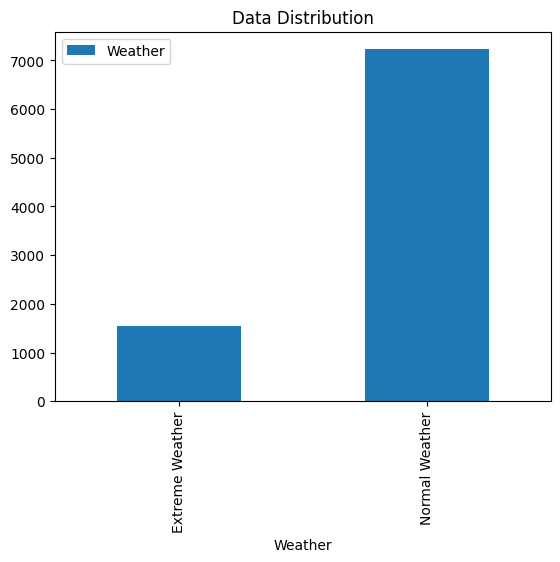

In [4]:
df_data_count = df.groupby(['Weather']).agg({'Weather': 'count'})
df_data_count.plot.bar()
plt.title("Data Distribution")
df_data_count

Text(0.5, 1.0, 'Correlation of Features with target variable y')

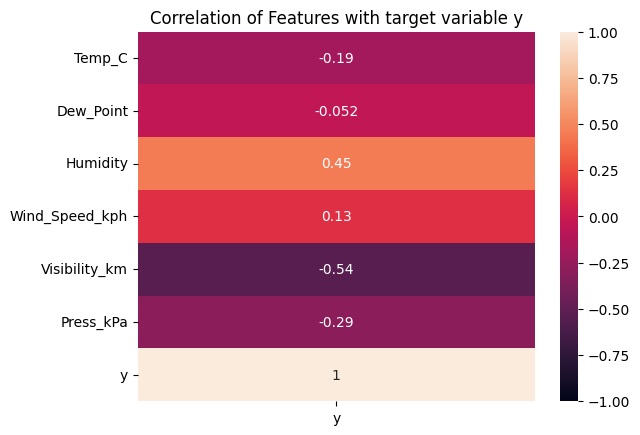

In [5]:
# only considering Temp_C, Dew_Point, Humidity, Wind_Speed_kph,Visibility_km, Press_kPa for our analysis 
#plotting correlation with target variable y.
df_temp = df[['Temp_C', 'Dew_Point', 'Humidity', 'Wind_Speed_kph','Visibility_km', 'Press_kPa', 'y']]
heatmap = sns.heatmap(df_temp.corr()[['y']], vmin=-1, vmax=1, annot=True)
plt.title("Correlation of Features with target variable y")

# Using logistic regression to predict the weather for features Humidity and Visibility

Text(0.5, 1.0, 'Humidity and Visibility with y')

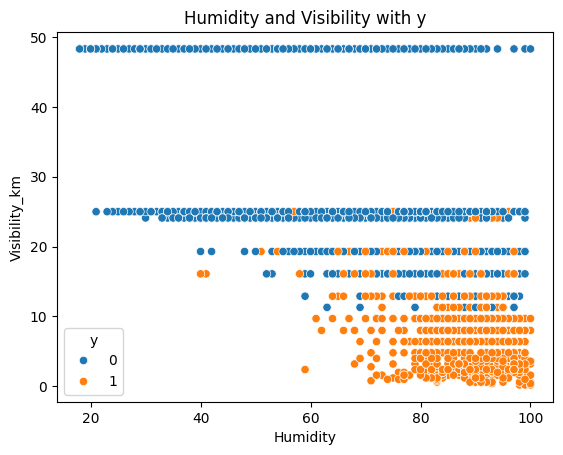

In [6]:
sns.scatterplot(df, x = df['Humidity'], y = df['Visibility_km'], hue = df['y'])
plt.title("Humidity and Visibility with y")

In [7]:
df_temp = df[['Humidity', 'Visibility_km', 'y']]
#dropping duplicates value
df_temp = df_temp.drop_duplicates()
y = df_temp['y']
X = df_temp[['Humidity', 'Visibility_km']]

In [8]:
def split_train_test(X, y, TEST_SIZE=0.33, RANDOM_STATE=42):
    return train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

'precision = [0.76056338 0.70098039]'

'recall = [0.46956522 0.89375   ]'

'f-score = [0.58064516 0.78571429]'

'support = [115 160]'

Text(0.5, 1.0, 'Confusion matrix for weights 0.5 and 0.9')

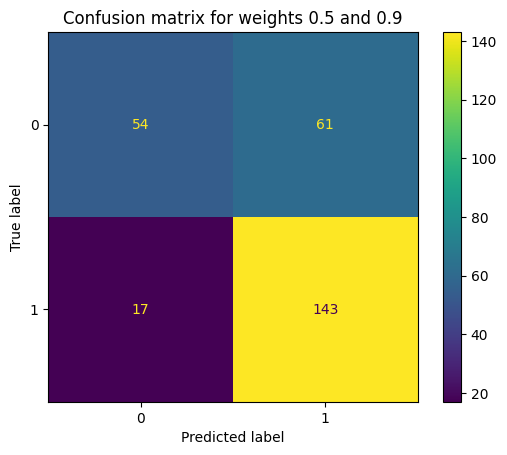

In [9]:
lm = LogisticRegression(class_weight={0:0.5, 1:0.9})
X_train, X_test, y_train, y_test = split_train_test(X, y)

#testing with the test dataset
lm.fit(X_train, y_train)
y_pred = lm.predict(X_test)
p,r,f,s = precision_recall_fscore_support(y_test, y_pred, labels=[0,1])
display('precision = {}'.format(p))
display('recall = {}'.format(r))
display('f-score = {}'.format(f))
display('support = {}'.format(s))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=lm.classes_)
disp.plot()
plt.title("Confusion matrix for weights 0.5 and 0.9")

'precision = [0.70103093 0.73595506]'

'recall = [0.59130435 0.81875   ]'

'f-score = [0.64150943 0.77514793]'

'support = [115 160]'

Text(0.5, 1.0, 'Confusion matrix for weights 0.7 and 1')

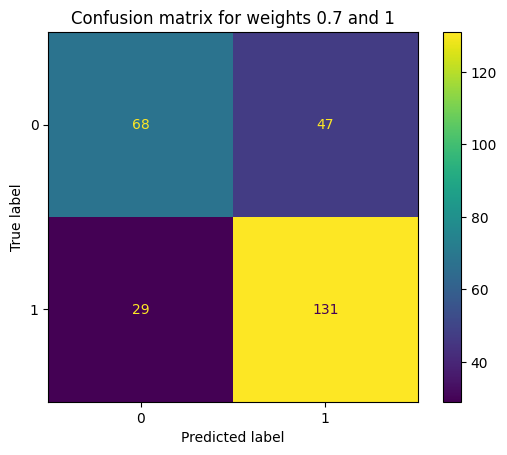

In [10]:
lm = LogisticRegression(class_weight={0:0.7, 1:1})
X_train, X_test, y_train, y_test = split_train_test(X, y)

#testing with the test dataset
lm.fit(X_train, y_train)
y_pred = lm.predict(X_test)
p,r,f,s = precision_recall_fscore_support(y_test, y_pred, labels=[0,1])
display('precision = {}'.format(p))
display('recall = {}'.format(r))
display('f-score = {}'.format(f))
display('support = {}'.format(s))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=lm.classes_)
disp.plot()
plt.title("Confusion matrix for weights 0.7 and 1")

Text(0.5, 1.0, 'Decision boundry using logistic regression')

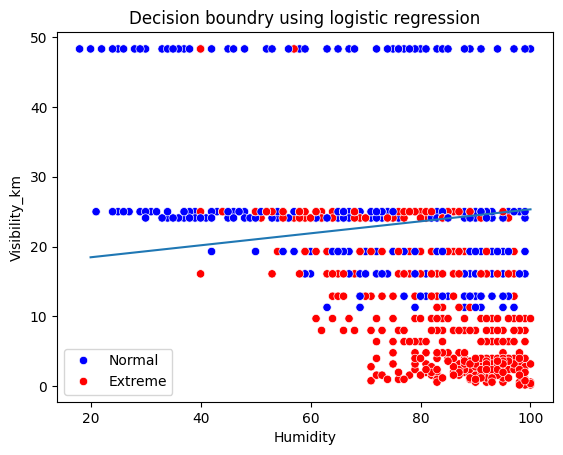

In [11]:
#Decision boundary using logistic regression
ax = sns.scatterplot(x=X_train['Humidity'], y=X_train['Visibility_km'], hue=y_train, palette = ["blue", "red"])

b0 = lm.intercept_[0]
b = lm.coef_[0]
Xdb = [20, 100]
ydb = [-(b0+b[0]*x)/b[1] for x in Xdb]
ax.plot(Xdb, ydb)

handles, labels = ax.get_legend_handles_labels()
labels = ["Normal", "Extreme"]
ax.legend(handles, labels)
ax.set(xlabel='Humidity', ylabel='Visibility_km')
plt.title("Decision boundry using logistic regression")

# Using SVM to predict weather

In [12]:
df_temp = df[['Humidity', 'Visibility_km', 'y']]
df_temp = df_temp.drop_duplicates()
y = df_temp['y']
X = df_temp[['Humidity', 'Visibility_km']]

In [13]:
# for linear
clf = svm.SVC(kernel='linear', class_weight={0:0.7, 1:1})
X_train, X_test, y_train, y_test = split_train_test(X, y)

clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
p,r,f,s = precision_recall_fscore_support(y_test, y_pred)
display('precision = {}'.format(p))
display('recall = {}'.format(r))
display('f-score = {}'.format(f))
display('support = {}'.format(s))

'precision = [0.74358974 0.7106599 ]'

'recall = [0.50434783 0.875     ]'

'f-score = [0.60103627 0.78431373]'

'support = [115 160]'

In [14]:
# for degree two
clf = svm.SVC(kernel='poly', degree=2, class_weight={0:0.7, 1:1})
X_train, X_test, y_train, y_test = split_train_test(X, y)

clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
p,r,f,s = precision_recall_fscore_support(y_test, y_pred)
display('precision = {}'.format(p))
display('recall = {}'.format(r))
display('f-score = {}'.format(f))
display('support = {}'.format(s))

'precision = [0.9375     0.65020576]'

'recall = [0.26086957 0.9875    ]'

'f-score = [0.40816327 0.78411911]'

'support = [115 160]'

<Figure size 640x480 with 0 Axes>

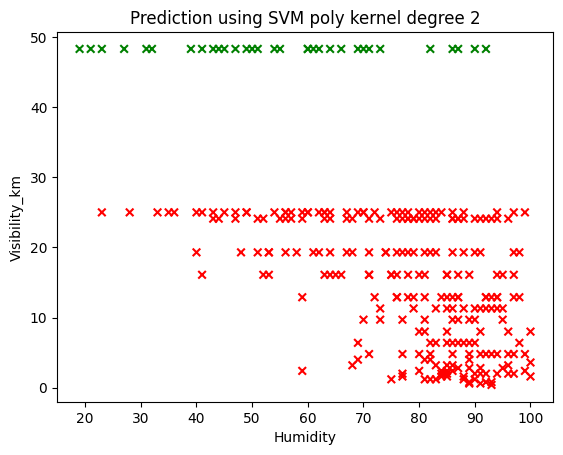

<Figure size 640x480 with 0 Axes>

In [15]:
# color = ['r' if y_ == 1 else 'g' for y_ in y_train]
# plt.scatter(X_train.Humidity, X_train.Visibility_km, c=color, s=30, marker='o')
color = ['r' if y_ == 1 else 'g' for y_ in y_pred]
plt.scatter(X_test.Humidity, X_test.Visibility_km, c=color, s=30, marker='x')
plt.xlabel('Humidity')
plt.ylabel('Visibility_km')
plt.title("Prediction using SVM poly kernel degree 2")
plt.figure()

Text(0.5, 1.0, 'Decision boundry using SVM poly kernel degree 2')

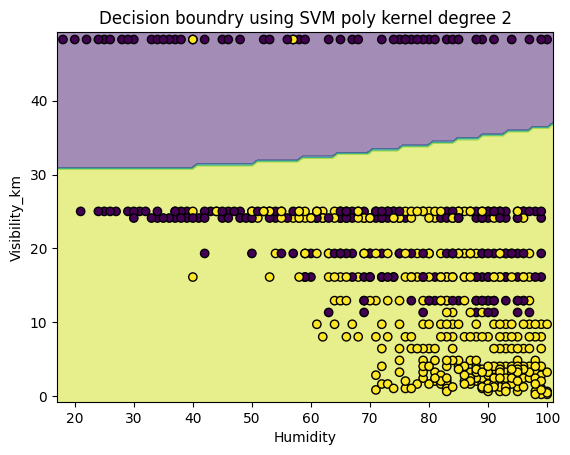

In [16]:
#decision boundary using poly kernel for degree 2
from sklearn.inspection import DecisionBoundaryDisplay
disp = DecisionBoundaryDisplay.from_estimator(
    clf.fit(X_train, y_train),
    X_train,
    response_method="predict",
    xlabel='Humidity',
    ylabel='Visibility_km',
    alpha=0.5,
)
# print(X_train[:, 0])
disp.ax_.scatter(X_train['Humidity'].values, X_train['Visibility_km'].values, c=y_train, edgecolor="k")
plt.title("Decision boundry using SVM poly kernel degree 2")

In [17]:
# for degree three
clf = svm.SVC(kernel='poly', degree=3, class_weight={0:0.7, 1:1})
X_train, X_test, y_train, y_test = split_train_test(X, y)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
p,r,f,s = precision_recall_fscore_support(y_test, y_pred)
display('precision = {}'.format(p))
display('recall = {}'.format(r))
display('f-score = {}'.format(f))
display('support = {}'.format(s))

'precision = [0.9375     0.65020576]'

'recall = [0.26086957 0.9875    ]'

'f-score = [0.40816327 0.78411911]'

'support = [115 160]'

<Figure size 640x480 with 0 Axes>

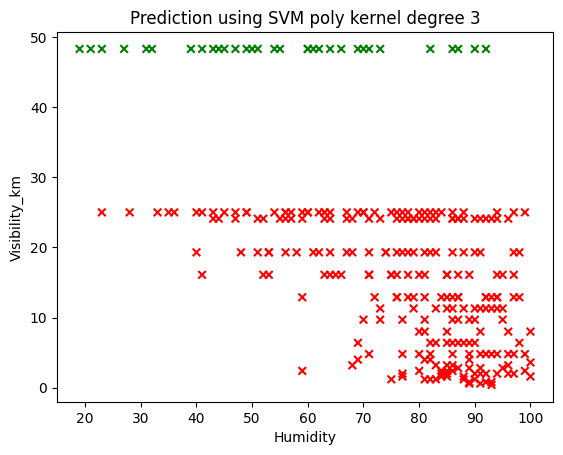

<Figure size 640x480 with 0 Axes>

In [18]:
color = ['r' if y_ == 1 else 'g' for y_ in y_pred]
plt.scatter(X_test.Humidity, X_test.Visibility_km, c=color, s=30, marker='x')
plt.xlabel('Humidity')
plt.ylabel('Visibility_km')
plt.title("Prediction using SVM poly kernel degree 3")
plt.figure()

Text(0.5, 1.0, 'Decision boundry using SVM poly kernel degree 3')

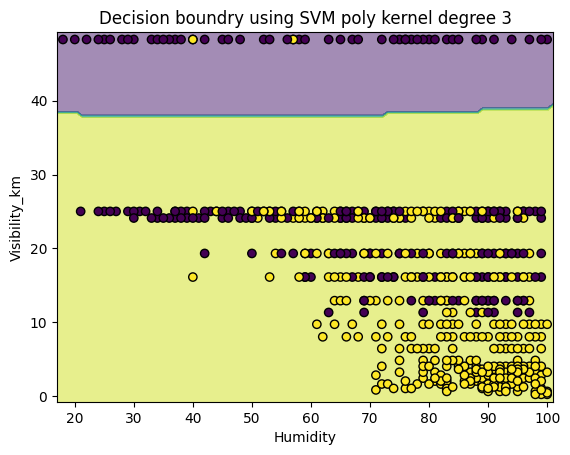

In [19]:
#decision boundary using poly kernel for degree 3
from sklearn.inspection import DecisionBoundaryDisplay
disp = DecisionBoundaryDisplay.from_estimator(
    clf.fit(X_train, y_train),
    X_train,
    response_method="predict",
    xlabel='Humidity',
    ylabel='Visibility_km',
    alpha=0.5,
)
# print(X_train[:, 0])
disp.ax_.scatter(X_train['Humidity'].values, X_train['Visibility_km'].values, c=y_train, edgecolor="k")
plt.title("Decision boundry using SVM poly kernel degree 3")

In [20]:
# for degree 4
clf = svm.SVC(kernel='poly', degree=4, class_weight={0:0.7, 1:1})
X_train, X_test, y_train, y_test = split_train_test(X, y)

clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
p,r,f,s = precision_recall_fscore_support(y_test, y_pred)
display('precision = {}'.format(p))
display('recall = {}'.format(r))
display('f-score = {}'.format(f))
display('support = {}'.format(s))

'precision = [0.9375     0.65020576]'

'recall = [0.26086957 0.9875    ]'

'f-score = [0.40816327 0.78411911]'

'support = [115 160]'

<Figure size 640x480 with 0 Axes>

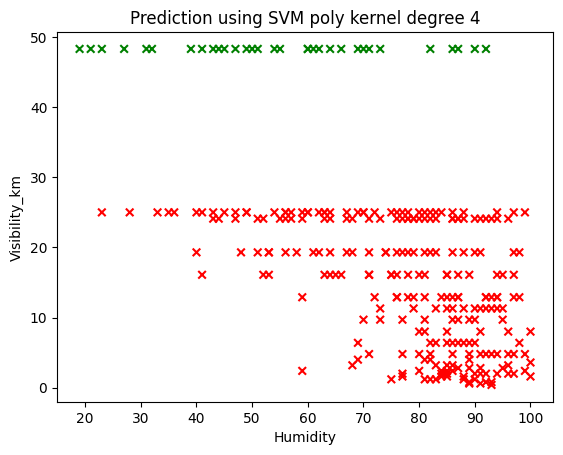

<Figure size 640x480 with 0 Axes>

In [21]:
color = ['r' if y_ == 1 else 'g' for y_ in y_pred]
plt.scatter(X_test.Humidity, X_test.Visibility_km, c=color, s=30, marker='x')
plt.xlabel('Humidity')
plt.ylabel('Visibility_km')
plt.title("Prediction using SVM poly kernel degree 4")
plt.figure()

Text(0.5, 1.0, 'Decision boundry using SVM poly kernel degree 4')

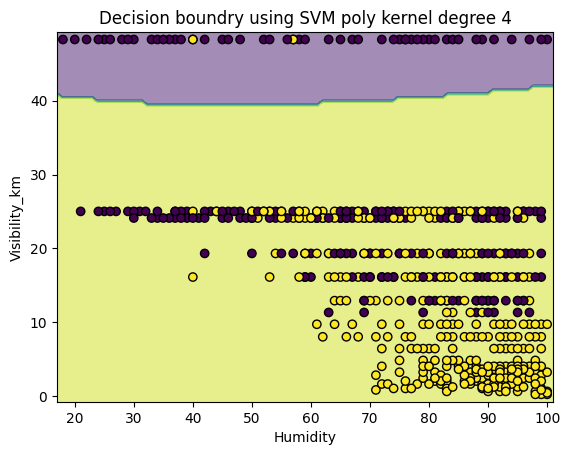

In [22]:
#decision boundary using poly kernel for degree 4
from sklearn.inspection import DecisionBoundaryDisplay
disp = DecisionBoundaryDisplay.from_estimator(
    clf.fit(X_train, y_train),
    X_train,
    response_method="predict",
    xlabel='Humidity',
    ylabel='Visibility_km',
    alpha=0.5,
)
# print(X_train[:, 0])
disp.ax_.scatter(X_train['Humidity'].values, X_train['Visibility_km'].values, c=y_train, edgecolor="k")
plt.title("Decision boundry using SVM poly kernel degree 4")

In [23]:
#rbf kernel
clf = svm.SVC(kernel='rbf', class_weight={0:0.7, 1:1})
X_train, X_test, y_train, y_test = split_train_test(X, y)

clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
p,r,f,s = precision_recall_fscore_support(y_test, y_pred)
display('precision = {}'.format(p))
display('recall = {}'.format(r))
display('f-score = {}'.format(f))
display('support = {}'.format(s))

'precision = [0.8490566  0.68468468]'

'recall = [0.39130435 0.95      ]'

'f-score = [0.53571429 0.79581152]'

'support = [115 160]'

<Figure size 640x480 with 0 Axes>

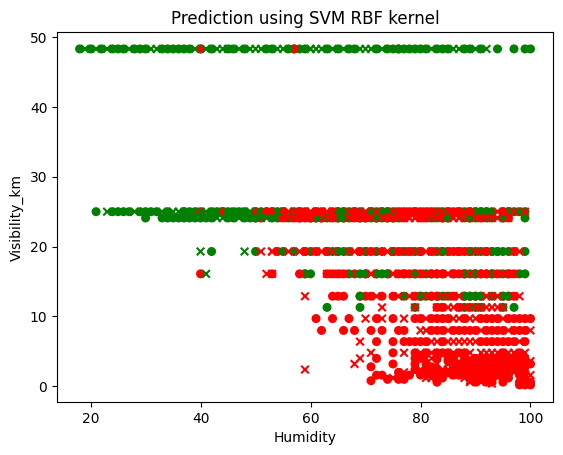

<Figure size 640x480 with 0 Axes>

In [24]:
color = ['r' if y_ == 1 else 'g' for y_ in y_train]
plt.scatter(X_train.Humidity, X_train.Visibility_km, c=color, s=30, marker='o')
color = ['r' if y_ == 1 else 'g' for y_ in y_pred]
plt.scatter(X_test.Humidity, X_test.Visibility_km, c=color, s=30, marker='x')
plt.xlabel('Humidity')
plt.ylabel('Visibility_km')
plt.title("Prediction using SVM RBF kernel")
plt.figure()

Text(0.5, 1.0, 'Decision boundry using SVM RBF kernel')

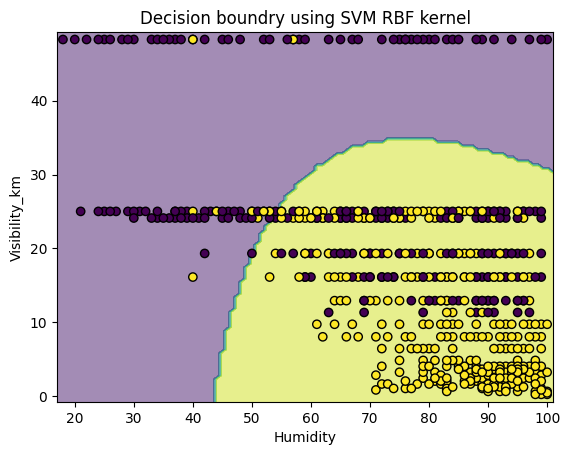

In [25]:
#decision boundary using rbf kernel
from sklearn.inspection import DecisionBoundaryDisplay
disp = DecisionBoundaryDisplay.from_estimator(
    clf.fit(X_train, y_train),
    X_train,
    response_method="predict",
    xlabel='Humidity',
    ylabel='Visibility_km',
    alpha=0.5,
)
# print(X_train[:, 0])
disp.ax_.scatter(X_train['Humidity'].values, X_train['Visibility_km'].values, c=y_train, edgecolor="k")
plt.title("Decision boundry using SVM RBF kernel")